# Améliorations de l’ILS pour le CVRPTW

Notre objectif reste la distance totale DIMACS, avec capacité homogène, fenêtres strictes sur le début du service, retour au dépôt, couverture unique et flotte maximale. Les données, les arrondis et les contraintes ne sont pas modifiés. Les références ne sont lues qu’après la résolution.

## Résultats exécutés et décision

Nous avons exécuté **144 résolutions de développement** sur six instances à 1 000 clients, deux graines et douze variantes, puis **72 résolutions de validation** sur douze autres instances, deux nouvelles graines et trois méthodes. Les phases d’un même solveur ne sont pas des répétitions indépendantes.

Le développement utilise les suffixes `_10_2`, les graines 1301 et 1302, et un plafond de 20 secondes. La validation utilise les suffixes `_10_3` et `_10_4`, les graines 1401 et 1402, et un plafond de 40 secondes. Ces géographies avaient déjà été étudiées dans le projet ; ce n’est pas un jeu entièrement inconnu. Aucun réglage n’est effectué à partir des résultats de cette nouvelle validation.

Les départs sont identiques par instance et graine. La construction est effectuée et chronométrée séparément pour chaque résolution ; le total comprend construction et recherche. Le préchauffage de compilation est hors budget. Chaque processus de calcul est fixé à un cœur logique distinct, avec un maximum de six processus. Le solveur de partitionnement peut terminer avant sa limite : les durées effectives sont publiées.

| Méthode | Essais | Gap moyen % | Écart-type | Pire gap % | Sous 6 % | Sous 7 % | Recherche s | Total s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ILS de référence | 24 | 10,127 | 5,903 | 25,086 | 7 | 11 | 40,008 | 44,422 |
| ILS–partitionnement | 24 | 10,355 | 6,443 | 28,012 | 9 | 11 | 38,039 | 42,422 |
| 64 voisins | 24 | 11,524 | 8,082 | 30,793 | 8 | 11 | 40,008 | 44,439 |

L’ILS de référence obtient 10.127 % de gap moyen sur ces 24 essais. La plus petite moyenne observée est 10.127 % pour ILS de référence. Ce minimum observé ne suffit pas, à lui seul, à démontrer une supériorité générale. Toutes les solutions de ces campagnes ont été vérifiées réalisables.

Les essais ne justifient pas de remplacer le moteur ILS de référence par défaut. Les nouvelles variantes restent expérimentales et leurs régressions sont conservées.

## Ce qui a été développé

**Échanges de blocs et RVND.** Le module `algo/rvnd.py` ajoute Swap(2,1), Swap(1,2) et Swap(2,2). Il calcule d’abord la variation des liaisons, filtre la capacité, puis vérifie entièrement les horaires des deux tournées modifiées. La RVND explore les voisinages dans un ordre aléatoire et réinitialise leur liste après une amélioration. Les déplacements de chaînes utilisent au plus trois clients. L’énumération exhaustive de petits exemples contrôle l’existence des améliorations, y compris avec fenêtres serrées.

**Perturbations variables.** `algo/ils_rvnd.py` augmente le nombre de mouvements complets et le nombre de voisins après stagnation. La solution courante et la meilleure archive sont séparées ; seule une solution complète et réalisable peut être acceptée. Une détérioration bornée par un seuil sert à explorer. Le meilleur résultat retourné ne peut pas être plus mauvais que le départ fourni. Cette intégration complète a régressé pendant le développement : son intérêt théorique ne constitue pas une amélioration démontrée dans notre code.

**Relais et finition.** `algo/relay.py` teste soit ILS puis recuit sur mouvements directs, soit ILS puis RVND. Le budget est partagé et non additionné. Ces variantes ne sont pas retenues comme remplacements sur la base de leurs moyennes de développement.

**Réglages ciblés.** La force de perturbation (1 contre 4), les voisins (64 contre 24) et le budget par groupe (0,05, 0,2 ou 0,6 seconde) sont testés séparément. Élargir le voisinage ouvre des mouvements mais augmente leur coût ; renforcer un composant n’améliore donc pas automatiquement le résultat à temps limité.

**ILS avec partitionnement.** `algo/ils_sp.py` consacre 95 % du budget disponible à quatre phases ILS successives, puis réserve au plus 5 secondes au choix des tournées. Les phases continuent la meilleure solution de la phase précédente avec une nouvelle graine. Toutes les tournées stockées proviennent de solutions réalisables produites par notre recherche ; aucune solution de référence n’est utilisée.

Pour les tournées archivées r, de distance c_r, nous minimisons $\sum_r c_r y_r$, sous $\sum_{r:i\in r}y_r=1$ pour chaque client i, $\sum_r y_r\leq K$ et $y_r\in\{0,1\}$. La capacité et les fenêtres sont déjà satisfaites par chaque tournée. La résolution utilise SciPy/HiGHS. Son écart relatif demandé est 0,1 % **dans l’archive seulement** : ce n’est pas le gap à la BKS ni une preuve d’optimalité du CVRPTW. En absence de solution du solveur dans le délai, l’archive réalisable précédente est conservée.

## Statistiques et lecture du gap

Le gap d’un essai est $100(D-D_{BKS})/D_{BKS}$, avec la même convention DIMACS pour les deux distances. La moyenne est la moyenne arithmétique des 24 gaps d’une méthode, sans sélectionner les meilleures graines. Chaque instance a le même poids puisqu’elle possède deux répétitions. Le nombre de véhicules reste une contrainte maximale ; il ne remplace pas l’objectif de distance.

L’écart-type du tableau décrit la dispersion des essais sur plusieurs instances : il mélange difficulté des cas et variabilité des graines. Le fichier `instances.csv` fournit aussi la dispersion par instance. Deux graines restent insuffisantes pour estimer finement cette variabilité.

Les différences appariées et un bootstrap exploratoire par instance sont fournis dans `paired_analysis.json`. Les douze instances sont rééchantillonnées en conservant ensemble leurs graines ; traiter tous les essais comme indépendants sous-estimerait l’incertitude. L’intervalle ne constitue pas une garantie de résultat sur toute la famille d’instances.

| instance | ILS de référence | 64 voisins | ILS–partitionnement |
| --- | --- | --- | --- |
| C1_10_3 | 3,802 | 3,203 | 3,029 |
| C1_10_4 | 4,088 | 3,808 | 3,946 |
| C2_10_3 | 10,503 | 12,914 | 11,538 |
| C2_10_4 | 13,366 | 12,712 | 13,494 |
| R1_10_3 | 6,789 | 6,449 | 6,519 |
| R1_10_4 | 5,528 | 6,705 | 6,033 |
| R2_10_3 | 11,255 | 12,690 | 11,910 |
| R2_10_4 | 16,654 | 29,216 | 18,876 |
| RC1_10_3 | 6,032 | 6,185 | 6,038 |
| RC1_10_4 | 5,473 | 5,093 | 4,969 |
| RC2_10_3 | 15,523 | 15,577 | 15,451 |
| RC2_10_4 | 22,509 | 23,736 | 22,462 |

## Protocole d’ablation

| Variante | Essais | Gap moyen % | Pire gap % |
| --- | --- | --- | --- |
| ILS de référence | 12 | 6,614 | 10,817 |
| Recuit seul | 12 | 10,435 | 19,082 |
| RVND fixe | 12 | 7,931 | 13,579 |
| ILS–partitionnement | 12 | 6,594 | 13,384 |
| Perturbation réduite | 12 | 7,196 | 12,423 |
| Groupes : 0,6 s | 12 | 9,281 | 13,783 |
| RVND sans blocs | 12 | 12,579 | 20,783 |
| ILS puis RVND | 12 | 7,082 | 13,210 |
| Relais ILS–recuit | 12 | 8,905 | 14,360 |
| RVND complète | 12 | 11,640 | 18,544 |
| Groupes : 0,05 s | 12 | 7,427 | 14,158 |
| 64 voisins | 12 | 6,653 | 11,552 |

Les comparaisons de RVND complète, fixe et sans blocs isolent partiellement l’intérêt de l’adaptation et des blocs dans cette architecture. Les différences entre cette architecture et l’ancien moteur ne sont pas attribuées au seul ajout d’un opérateur : l’ordonnancement de la recherche change aussi.

## Reproduction et limites

Les fichiers JSON bruts, protocoles, empreintes et sources figées sont dans `results/optimization_v5/`. Les moyennes et tableaux se recalculent avec `python scripts/analyze_ils_v5.py`. La commande `python scripts/benchmark_ils_v5.py --role validation --seconds 40 --seeds 1401 1402 --variants baseline_ils wide ils_sp` reprend les essais terminés ; une reproduction neuve doit utiliser `--label nouveau_lot`. Le même matériel et les mêmes versions restent nécessaires pour des temps comparables. Le manifeste des données permet de vérifier les fichiers d’instances.

Cette étude ne démontre pas un gap inférieur à 6 % sur toutes les grandes instances. Elle ne démontre pas non plus le passage à plusieurs milliers de clients, ni le trafic variable. Le calcul plus rapide par résumés de segments reste une piste future : il n’est pas présenté comme déjà implémenté.

## Sources méthodologiques

- [Ribas et ses coauteurs : ILS, RVND et partitionnement pour le VRPTW](https://luizsatoru.github.io/conteudo/artigos/PAPER%20IESM2011-SABIR.pdf). L’article traite capacité et fenêtres, mais ses expériences portent sur 100 clients ; sa colonne « gap » mesure la dispersion par rapport à son meilleur essai, pas notre gap moyen à la BKS.
- [Vidal et ses coauteurs : évaluation et recherche locale multi-attributs](https://www.cirrelt.ca/documentstravail/cirrelt-2012-23.pdf). Les résumés de portions de tournée motivent une future accélération sûre, après profilage.
- [Kool et ses coauteurs : voisinages et intensification pour le VRPTW](https://wouterkool.github.io/pdf/paper-kool-hgs-vrptw.pdf). Les performances du solveur complet ne sont pas attribuées à notre ILS.


### Archive combinée à effort supérieur

Une étude distincte réunit seize trajectoires admissibles par instance : dix résolutions ILS/recuit de v2 et six résolutions de la nouvelle validation. Les tournées sont recombinées pendant au plus deux secondes, puis la solution reçoit 60 secondes supplémentaires : un tiers d’ILS et deux tiers de recuit sur mouvements directs, graine 1501. Les résolutions d’origine sont toutes comptées dans l’effort, avec la construction v2 partagée comptée une seule fois par paire et les constructions v5 effectivement répétées.

Cette archive atteint **5.106 % de gap moyen**, avec un pire cas de **12.086 %** et un effort cumulé moyen de **745.7 secondes par instance**. Il s’agit d’une solution combinée par instance et de douze intensifications supplémentaires, pas d’une moyenne de répétitions indépendantes ni d’un solveur obtenant ce résultat en 40 ou 60 secondes. La baisse de 6,600 % à cette moyenne mesure l’amélioration de cette archive précise ; elle ne démontre pas la supériorité du relais sur un autre algorithme à effort total égal. L’objectif sous 6 % est atteint en moyenne dans ce périmètre coûteux, pas sur chaque instance ni dans le protocole court.

| Instance | Avant intensification % | Archive finale % | Effort cumulé s |
| --- | --- | --- | --- |
| C1_10_3 | 1,668 | 1,563 | 745,446 |
| C1_10_4 | 2,878 | 2,309 | 739,547 |
| C2_10_3 | 4,069 | 3,080 | 742,431 |
| C2_10_4 | 8,579 | 5,000 | 745,518 |
| R1_10_3 | 4,568 | 3,078 | 739,793 |
| R1_10_4 | 3,741 | 3,009 | 739,516 |
| R2_10_3 | 9,512 | 9,049 | 754,095 |
| R2_10_4 | 13,397 | 10,443 | 754,827 |
| RC1_10_3 | 4,583 | 3,236 | 738,519 |
| RC1_10_4 | 3,439 | 2,867 | 738,931 |
| RC2_10_3 | 10,118 | 5,549 | 752,397 |
| RC2_10_4 | 12,652 | 12,086 | 757,287 |

Les résultats complets sont dans `results/optimization_v5/portfolio_intensified/`. L’archive initiale reste disponible dans `portfolio/` ; aucune référence BKS n’est passée au moteur de recherche.


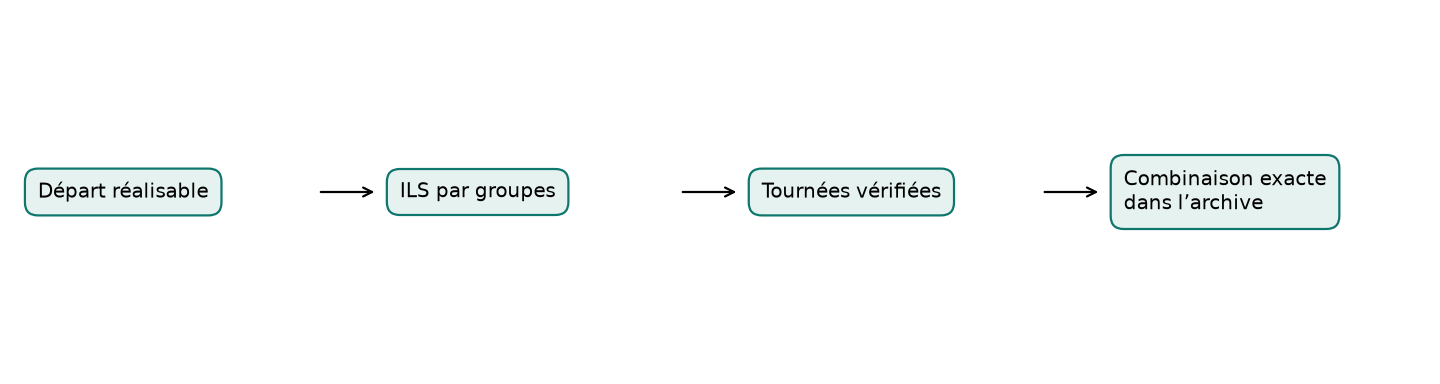

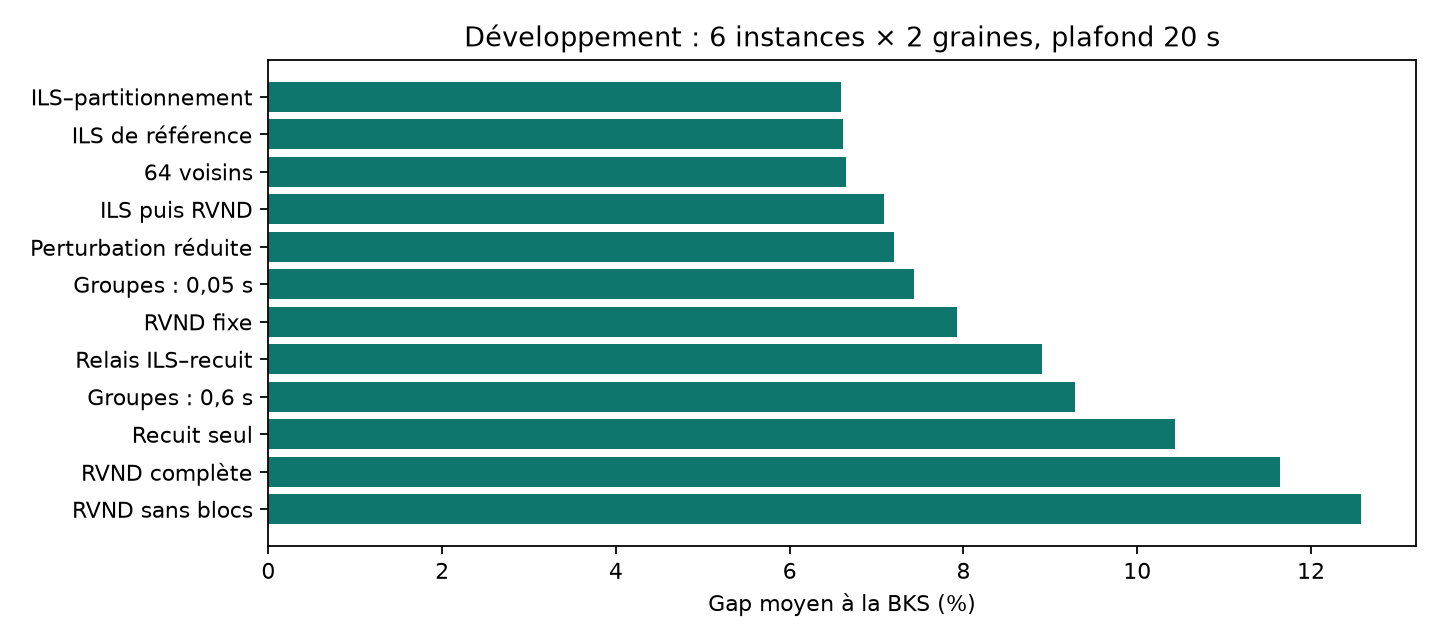

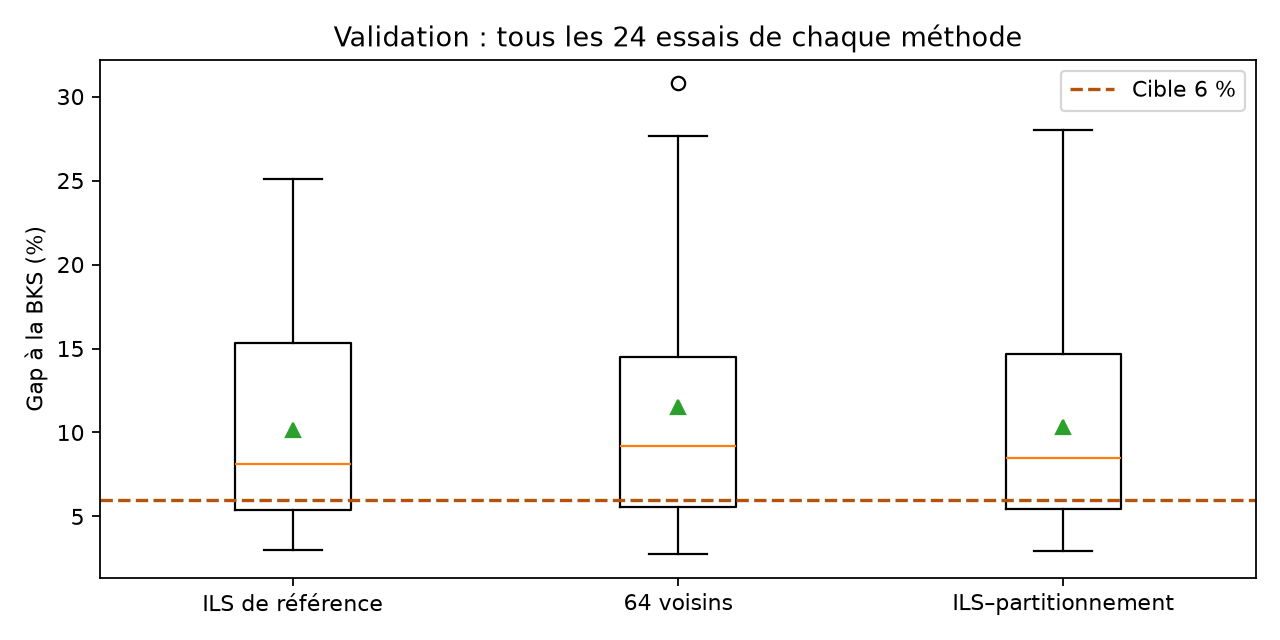

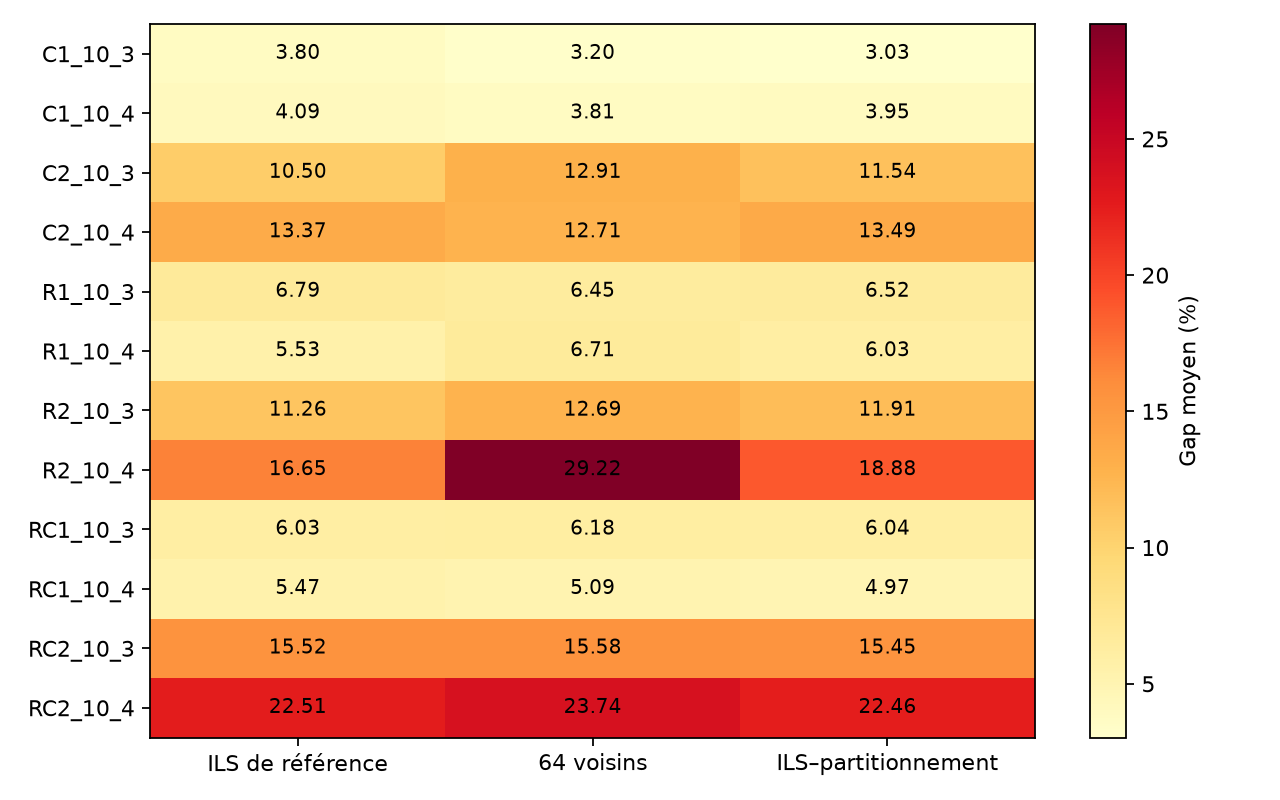

In [1]:
from pathlib import Path
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'algo/ils_sp.py').exists())
display(Image(filename=str(ROOT/'livraison/ils_v5_figures/scheme.png')))
display(Image(filename=str(ROOT/'livraison/ils_v5_figures/development.png')))
display(Image(filename=str(ROOT/'livraison/ils_v5_figures/validation.png')))
display(Image(filename=str(ROOT/'livraison/ils_v5_figures/instances.png')))